# CSCI1409 Deep Learning · Week 9 Homework (starter)
## Repair a parcel-label reader

**Individual · about 2.5–3 hours · CPU only.** The full task description is in the handout *CSCI1409_Week09_OCR_Homework*. In this notebook you **write code and run it**: there is no hand calculation anywhere.

**Marks (internal guide):** Part 0 reading 15 · Part 1 CTC decoder 15 · Part 2 trustworthy scoring 25 · Part 3 two fixes 30 · Part 4 evidence 15.

**Rules**
1. Do the **reading first** (Part 0). Answer in your own words and name the source.
2. Cells marked **PROVIDED** are given: do not edit them. Cells marked **TODO** are yours.
3. Use validation images to make choices. **Do not run OCR on test images until your recipe is frozen** (Part 3).
4. Write the code and the explanations yourself; Name your sources at the end.
5. Before you submit: **Kernel → Restart & Run All**, so every number comes from this run.

## Setup (PROVIDED)
You need the **Tesseract** program (a separate engine; `pip` alone is not enough) with English data.
- **Google Colab:** run `!apt-get install -y tesseract-ocr` and `!pip install rapidfuzz` once, then restart the runtime.
- **Your own computer:** install Tesseract (see the setup link in the handout) and `pip install rapidfuzz pandas matplotlib pillow`.
- Unpack the student pack (the folder with `manifest.csv` and the images) next to this notebook.

In [10]:
# PROVIDED: setup and helpers. Do not edit.
import os, io, glob, json, shutil, subprocess, datetime
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
from rapidfuzz.distance import Levenshtein

assert shutil.which("tesseract"), "Tesseract is not installed: see the setup note above."
print(subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.splitlines()[0])
assert "eng" in subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True).stdout, "English language data missing."

hits = glob.glob("**/manifest.csv", recursive=True)
assert hits, "manifest.csv not found: unpack the student pack next to this notebook."
PACK_DIR = os.path.dirname(hits[0])
manifest = pd.read_csv(hits[0])
REF_COL = next(c for c in ("reference", "target", "text", "label") if c in manifest.columns)   # column with the true string
CONDITIONS = ["clean", "blur", "rotation", "shadow"]
val_rows  = manifest[manifest["split"].astype(str).str.startswith("val")]
test_rows = manifest[manifest["split"].astype(str).str.startswith("test")]
_files = {os.path.basename(p): p for p in glob.glob(os.path.join(PACK_DIR, "**", "*.*"), recursive=True)}

def load_image(filename):
    """Every image is loaded as grayscale. This is part of loading, not of your recipes."""
    return Image.open(_files[filename]).convert("L")

def ocr(img):
    """Fixed OCR call: Tesseract, English, LSTM engine, one text line (--oem 1 --psm 7). Do not change."""
    buf = io.BytesIO(); img.save(buf, format="PNG")
    r = subprocess.run(["tesseract", "stdin", "stdout", "-l", "eng", "--oem", "1", "--psm", "7"],
                       input=buf.getvalue(), capture_output=True)
    return r.stdout.decode("utf-8", errors="replace").strip()

def show(images, titles, width=3.2):
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), 1.6), squeeze=False)
    for ax, im, t in zip(axes[0], images, titles):
        ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=8); ax.axis("off")
    plt.show()

def report_table(df):
    """Table per condition and overall: images, reference characters, edits, corpus CER, exact match. Uses YOUR score()."""
    rows = []
    for name, part in [(c, df[df["condition"] == c]) for c in CONDITIONS] + [("ALL", df)]:
        if len(part) == 0: continue
        s = score(list(part["norm_reference"]), list(part["norm_prediction"]))
        rows.append({"condition": name, "images": s["images"], "ref_chars": s["chars"], "edits": s["edits"],
                     "corpus_CER": round(s["cer"], 3), "exact_match": f'{s["exact_n"]}/{s["images"]} ({100*s["exact_n"]/s["images"]:.0f}%)'})
    return pd.DataFrame(rows).set_index("condition")

def freeze(config):
    """Writes chosen_config.json with a timestamp. Run it once, BEFORE any test OCR."""
    config = dict(config); config["frozen_at"] = datetime.datetime.now().isoformat(timespec="seconds")
    with open("chosen_config.json", "w") as f: json.dump(config, f, indent=2)
    print("Frozen at", config["frozen_at"])

def require_frozen():
    assert os.path.exists("chosen_config.json"), "Freeze your recipe (Part 3.4) BEFORE touching the test set."

PRED_COLUMNS = ["filename", "base_id", "split", "condition", "system", "reference", "raw_prediction",
                "norm_reference", "norm_prediction", "edits", "ref_length", "exact_match"]

def show_example(filename, base_df, fix_df):
    """Shows one test crop with the reference and both predictions."""
    b = base_df[base_df["filename"] == filename].iloc[0]; f = fix_df[fix_df["filename"] == filename].iloc[0]
    show([load_image(filename)], [f'{filename} | ref {b["norm_reference"]} | baseline "{b["norm_prediction"]}" ({b["edits"]} edits) | '
                                  f'fix "{f["norm_prediction"]}" ({f["edits"]} edits)'], width=9)

print("Pack:", PACK_DIR, "| images:", len(manifest), "| validation:", len(val_rows), "| test:", len(test_rows), "| reference column:", REF_COL)
manifest.head(3)

tesseract 5.5.4
Pack: week9_homework_data | images: 48 | validation: 24 | test: 24 | reference column: target


,filename,base_id,split,condition,target
0,images/V01_clean.png,V01,validation,clean,WB-4817
1,images/V01_blur.png,V01,validation,blur,WB-4817
2,images/V01_rotation.png,V01,validation,rotation,WB-4817


# Part 0 · Reading check (15 marks, about 40 minutes of reading)
Read **before** coding: the lecture slides; Hannun (2017) *Sequence Modeling with CTC* (distill.pub/2017/ctc: Introduction and the *Alignment* part); the Tesseract page *Improving the quality of the output* (the *Image processing* section); Shi, Bai, Yao (2015) *CRNN* (arxiv.org/abs/1507.05717: abstract, introduction, architecture figure).
Answer in 1–3 sentences each, in your own words, and end with the source, e.g. *(Hannun, Alignment)*. No source or copied wording: at most 1 of 3 marks.

**R1.** Why can one image classifier not read a whole label such as `COFFEE-55`? What changes between reading `7`, `BOOK` and `COFFEE-55`?

**Your answer:** *(write here, and name your source)*

**R2.** In a CRNN reader, what job does each part do: the CNN, the BiLSTM, and CTC? Why do we still need a text detector for a full photograph?

**Your answer:** *(write here, and name your source)*

**R3.** CTC decoding has two steps. Which two, in which order? What is the blank for, and why does `BOOK` need one between the two O's?

**Your answer:** *(write here, and name your source)*

**R4.** Name two image problems that the Tesseract documentation says can hurt recognition, and one fix for each.

**Your answer:** *(write here, and name your source)*

**R5.** Why report exact match as well as CER for a product code?

**Your answer:** *(write here, and name your source)*

# Part 1 · Build the CTC decoder (15 marks)
CTC turns a path of per-position symbols into text: **(1) merge adjacent identical symbols, (2) remove blanks.** `∅` is the blank symbol, not a space.

In [11]:
def ctc_collapse(path, blank="∅"):
    """path: list of token strings (letters and blanks). Returns the decoded string."""
    # TODO: step 1: merge adjacent identical tokens
    merged = []
    for tok in path:
        if not merged or tok != merged[-1]:
            merged.append(tok)
    # TODO: step 2: remove the blank tokens, then join into a string
    return "".join(tok for tok in merged if tok != blank)
    

In [12]:
# PROVIDED: checks. Passing is necessary; you must also be able to explain your code.
assert ctc_collapse([]) == ""                                   # empty path
assert ctc_collapse(["∅", "∅", "∅"]) == ""                      # only blanks
assert ctc_collapse(list("LLLL")) == "L"                        # adjacent repeats merge
assert ctc_collapse(["L", "L", "∅", "L", "L"]) == "LL"          # a blank keeps two identical letters
for p in (["B","B","∅","O","O","∅","O","K","K"], ["C","C","∅","A","A","T","T"], ["L","L","∅","L","L"], ["L","L","L","L"]):
    print("".join(p), "->", repr(ctc_collapse(p)))
print("All CTC checks passed")

BB∅OO∅OKK -> 'BOOK'
CC∅AATT -> 'CAT'
LL∅LL -> 'LL'
LLLL -> 'L'
All CTC checks passed


In [13]:
def wrong_collapse(path, blank="∅"):
    """The WRONG order: remove blanks first, then merge repeats."""
    # TODO: implement the wrong order (3-4 lines)
    without_blanks = [tok for tok in path if tok != blank]
    merged = []
    for tok in without_blanks:
        if not merged or tok != merged[-1]:
            merged.append(tok)
    return "".join(merged)


BOOK_PATH = ["B", "B", "∅", "O", "O", "∅", "O", "K", "K"]
# TODO: print ctc_collapse(BOOK_PATH) and wrong_collapse(BOOK_PATH) side by side
print(ctc_collapse(BOOK_PATH), wrong_collapse(BOOK_PATH))

BOOK BOK


In [14]:
# TODO: write two DIFFERENT paths (lists of tokens) that both decode to "BOOK" with your ctc_collapse
PATH_1 = ["B", "B", "∅", "O", "O", "∅", "O", "K", "K"]
PATH_2 = ["B", "∅", "O", "O", "∅", "O", "O", "∅", "K"]
# PROVIDED check
assert PATH_1 != PATH_2 and ctc_collapse(PATH_1) == "BOOK" and ctc_collapse(PATH_2) == "BOOK", "Fix your two paths"
print("OK")

OK


**Part 1 answer** (2–3 sentences): look at your `wrong_collapse` output. What goes wrong, and why does the blank have to be removed *after* merging?

**Your answer:** *(write here)*

# Part 2 · Build a baseline you can trust (25 marks)
Your scoring code must compare predictions with the reference text the same way every time and must not hide failures. Work with **validation images only** until Part 3.4.

### 2.1 Check the data (4 marks)

In [18]:
# TODO: write assert statements (each with a short message) that check:
#   - the manifest has 48 rows, 24 validation and 24 test
#   - every base_id appears in exactly ONE split
#   - every filename in the manifest exists (use _files)
#   - each split has all four conditions, 6 images each
assert len(manifest) == 48, "Manifest must have 48 rows"
assert len(val_rows) == 24, "Validation must have 24 rows"
assert len(test_rows) == 24, "Test must have 24 rows"
assert manifest.groupby("base_id")["split"].nunique().max() == 1, "base_id must appear in only one split"
assert manifest["filename"].map(os.path.basename).isin(_files).all(), "Every filename must exist"

for split in ["val", "test"]:
    rows = manifest[manifest["split"].astype(str).str.startswith(split)]
    counts = rows["condition"].value_counts()
    assert len(counts) == 4 and (counts == 6).all(), f"{split} must have 4 conditions with 6 images each"

print("Data checks passed")


Data checks passed


### 2.2 Normalize text (4 marks)
Convert to uppercase and remove **all** whitespace. Keep punctuation, hyphens and digits. Do **not** change `O` into `0` or `I` into `1`. Apply it to references **and** predictions.

In [19]:
def normalize(text):
    # TODO
    return "".join(str(text).upper().split())


In [20]:
# PROVIDED check
assert normalize(" wb-48 17\n") == "WB-4817" and normalize("b0ok") == "B0OK" and normalize("") == ""
print("normalize OK")

normalize OK


### 2.3 Corpus CER and exact match (8 marks)
`corpus_CER = total edits / total reference characters` and `exact match = identical normalized pairs / images`. Use `Levenshtein.distance(a, b)` for the edit count of one pair. Pass **already normalized** strings.

In [21]:
def score(refs, preds):
    """refs, preds: equal-length lists of normalized strings.
    Return a dict with keys: images, chars, edits, cer, exact_n."""
    total_edits = 0
    total_chars = 0
    exact_n = 0

    for ref, pred in zip(refs, preds):
        edits = Levenshtein.distance(ref, pred)
        total_edits += edits
        total_chars += len(ref)

        if ref == pred:
            exact_n += 1

    return {
        "images": len(refs),
        "chars": total_chars,
        "edits": total_edits,
        "cer": total_edits / total_chars if total_chars else 0.0,
        "exact_n": exact_n
    }

In [22]:
# PROVIDED check on three toy pairs (BOOK->BOK, CAT->CATS, R7->R7)
s = score(["BOOK", "CAT", "R7"], ["BOK", "CATS", "R7"])
assert (s["images"], s["chars"], s["edits"], s["exact_n"]) == (3, 9, 2, 1) and abs(s["cer"] - 2/9) < 1e-9, s
print("score OK:", s)

score OK: {'images': 3, 'chars': 9, 'edits': 2, 'cer': 0.2222222222222222, 'exact_n': 1}


In [23]:
# TODO: for the same three pairs, compute the AVERAGE of the three per-image CERs (edits / length of that reference)
# and print it next to s["cer"]. They are different numbers: which one does this course use, and why?
per_image_cer = [
    Levenshtein.distance(ref, pred) / len(ref)
    for ref, pred in zip(["BOOK", "CAT", "R7"], ["BOK", "CATS", "R7"])
]

average_cer = sum(per_image_cer) / len(per_image_cer)

print("Corpus CER:", s["cer"])
print("Average per-image CER:", average_cer)

# The course uses corpus CER because it divides total edits by total reference characters.

Corpus CER: 0.2222222222222222
Average per-image CER: 0.19444444444444442


**2.3 answer** (2 sentences): why is the corpus CER not the average of per-image CERs, and why must an empty prediction stay in the table?

**Your answer:** *(write here)*

### 2.4 Run the baseline on validation (9 marks)
One function runs any system (a preprocessing function, or none) on a set of rows. Every image must give one row, **including empty OCR outputs**.

In [26]:
def run_system(rows, preprocess=None, system="baseline"):
    """rows: a slice of `manifest`. preprocess: a function img -> img, or None for the baseline.
    Returns a DataFrame with one row per image and the columns in PRED_COLUMNS."""
    out = []
    for _, r in rows.iterrows():
        img = load_image(os.path.basename(r["filename"]))

        # TODO: apply `preprocess` if it is not None
        if preprocess is not None:
            img = preprocess(img)

        # TODO: raw = ocr(img)
        raw = ocr(img)

        # TODO: normalize the reference (r[REF_COL]) and the raw prediction; count edits; exact_match True/False
        ref = normalize(r[REF_COL])
        pred = normalize(raw)
        edits = Levenshtein.distance(ref, pred)

        out.append({
            "filename": r["filename"],
            "base_id": r["base_id"],
            "split": r["split"],
            "condition": r["condition"],
            "system": system,
            "reference": r[REF_COL],
            "raw_prediction": raw,
            "norm_reference": ref,
            "norm_prediction": pred,
            "edits": edits,
            "ref_length": len(ref),
            "exact_match": ref == pred
        })

    return pd.DataFrame(out, columns=PRED_COLUMNS)


In [27]:
# TODO: run the baseline on the 24 validation images -> val_base ; print report_table(val_base) ;
# show the 5 rows with the most edits (val_base.sort_values("edits", ascending=False).head(5))

val_base = run_system(val_rows, system="baseline")

print(report_table(val_base))

val_base.sort_values("edits", ascending=False).head(5)

           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
clean           6         47      0       0.000   6/6 (100%)
blur            6         47      0       0.000   6/6 (100%)
rotation        6         47     43       0.915     0/6 (0%)
shadow          6         47     43       0.915     0/6 (0%)
ALL            24        188     86       0.457  12/24 (50%)


,filename,base_id,split,condition,system,reference,raw_prediction,norm_reference,norm_prediction,edits,ref_length,exact_match
22,images/V06_rotation.png,V06,validation,rotation,baseline,ROOM-406,,ROOM-406,,8,8,False
6,images/V02_rotation.png,V02,validation,rotation,baseline,BOOK-220,,BOOK-220,,8,8,False
19,images/V05_shadow.png,V05,validation,shadow,baseline,BOX-6072,ire,BOX-6072,IRE,8,8,False
11,images/V03_shadow.png,V03,validation,shadow,baseline,KBTU-903,os,KBTU-903,OS,8,8,False
18,images/V05_rotation.png,V05,validation,rotation,baseline,BOX-6072,,BOX-6072,,8,8,False


**2.4 answer** (2–3 sentences): which condition is hardest for the baseline, and what do you actually see in the failing rows (empty? partly right? wrong letters?)

**Your answer:** *(write here)*

# Part 3 · Compare two fixes fairly (30 marks)
You may change the **image**, never the OCR call or the scoring. A recipe may look at pixels only: not at the filename, base_id, split, condition or reference text.

### 3.1 Predict first (4 marks)
Before running any fix: which condition will be hardest, and which operation might help it? Give a reason from what you see in the images.

**Your prediction:** *(write here, 2–3 sentences)*

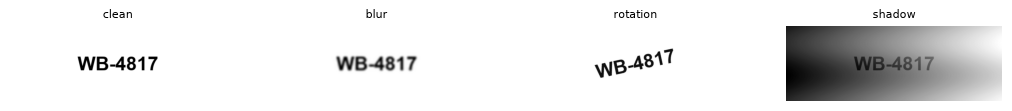

In [29]:
# PROVIDED: look at one validation crop per condition (no OCR needed)
sample = [val_rows[val_rows["condition"] == c].iloc[0]["filename"] for c in CONDITIONS]
show([load_image(os.path.basename(f)) for f in sample], CONDITIONS)

### 3.2 Write exactly two recipes (8 marks)
Each recipe is a function `img -> img` using **at most three** Pillow operations. Ideas: `img.resize((w*2, h*2), Image.LANCZOS)`, `ImageOps.autocontrast(img)`, `img.filter(ImageFilter.SHARPEN)`, `img.filter(ImageFilter.MedianFilter(3))`, `img.point(lambda v: 255 if v > T else 0)` (threshold), `ImageOps.expand(img, border=20, fill=255)` (white border). Docs: pillow.readthedocs.io (ImageOps, ImageFilter).

In [30]:
def fix_a(img):
    # TODO: your first recipe (<= 3 operations)
    img = ImageOps.autocontrast(img)
    img = img.filter(ImageFilter.SHARPEN)
    return img

def fix_b(img):
    # TODO: your second recipe (<= 3 operations), different from fix_a
    img = ImageOps.autocontrast(img)
    img = img.point(lambda p: 255 if p > 160 else 0)
    return img

trials = []   # keep a log: trials.append(("short description", validation CER)); at most 6 trial runs in total

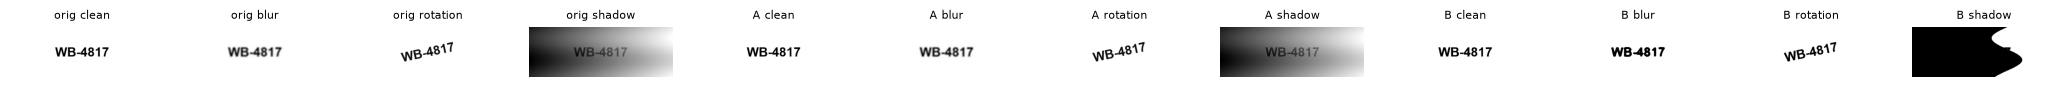

In [41]:
# PROVIDED: see what your recipes do to one crop per condition
show([load_image(os.path.basename(f)) for f in sample] + [fix_a(load_image(os.path.basename(f))) for f in sample] + [fix_b(load_image(os.path.basename(f))) for f in sample],
     [f"orig {c}" for c in CONDITIONS] + [f"A {c}" for c in CONDITIONS] + [f"B {c}" for c in CONDITIONS], width=2.2)

### 3.3 Compare on validation (6 marks)

In [42]:
# TODO: run fix_a and fix_b on the 24 validation images -> val_a, val_b (system names "fix_a", "fix_b")
val_a = run_system(val_rows, preprocess=fix_a, system="fix_a")
val_b = run_system(val_rows, preprocess=fix_b, system="fix_b")

# TODO: print report_table for val_base, val_a, val_b (same format)
print("BASELINE")
print(report_table(val_base))

print("FIX A")
print(report_table(val_a))

print("FIX B")
print(report_table(val_b))

BASELINE
           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
clean           6         47      0       0.000   6/6 (100%)
blur            6         47      0       0.000   6/6 (100%)
rotation        6         47     43       0.915     0/6 (0%)
shadow          6         47     43       0.915     0/6 (0%)
ALL            24        188     86       0.457  12/24 (50%)
FIX A
           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
clean           6         47      0       0.000   6/6 (100%)
blur            6         47      0       0.000   6/6 (100%)
rotation        6         47     36       0.766     0/6 (0%)
shadow          6         47     47       1.000     0/6 (0%)
ALL            24        188     83       0.441  12/24 (50%)
FIX B
           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
cle

### 3.4 Choose and freeze (6 marks)
Choose by **lowest validation corpus CER** (tie: higher exact match). Then run `freeze(...)`: it writes `chosen_config.json` with a timestamp.

In [46]:
# TODO: set CHOSEN to "fix_a" or "fix_b"
CHOSEN = "fix_b"

config = {"chosen": CHOSEN,
          "operations": "ImageOps.autocontrast, point(lambda p: 255 if p > 160 else 0)",
          "ocr": "tesseract --oem 1 --psm 7, lang eng",
          "normalization": "uppercase, remove whitespace",
          "reason": "fix_b achieved the lowest validation CER (0.415) and the highest exact match (54%), compared with fix_a (0.441, 50%) and baseline (0.457, 50%)."}

freeze(config)  # uncomment and run ONCE, after you decided

Frozen at 2026-11-07T04:47:26


### 3.5 Test, run once (6 marks)

In [47]:
require_frozen()      # PROVIDED guard: stops here if you did not freeze first

# TODO: run the baseline and the CHOSEN recipe on the 24 test images -> test_base, test_final
test_base = run_system(test_rows, system="baseline")

if CHOSEN == "fix_a":
    test_final = run_system(test_rows, preprocess=fix_a, system="fix_a")
else:
    test_final = run_system(test_rows, preprocess=fix_b, system="fix_b")

# TODO: print report_table for both. Do NOT tune anything after this.
print("TEST BASELINE")
print(report_table(test_base))

print("TEST FINAL")
print(report_table(test_final))

TEST BASELINE
           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
clean           6         49      0       0.000   6/6 (100%)
blur            6         49      0       0.000   6/6 (100%)
rotation        6         49     22       0.449     0/6 (0%)
shadow          6         49     43       0.878     0/6 (0%)
ALL            24        196     65       0.332  12/24 (50%)
TEST FINAL
           images  ref_chars  edits  corpus_CER  exact_match
condition                                                   
clean           6         49      0       0.000   6/6 (100%)
blur            6         49      0       0.000   6/6 (100%)
rotation        6         49     27       0.551     0/6 (0%)
shadow          6         49     48       0.980     0/6 (0%)
ALL            24        196     75       0.383  12/24 (50%)


In [48]:
# PROVIDED: saves all 120 required rows (validation: baseline + fix_a + fix_b = 72; test: baseline + chosen = 48)
all_preds = pd.concat([val_base, val_a, val_b, test_base, test_final], ignore_index=True)
assert len(all_preds) == 120 and list(all_preds.columns) == PRED_COLUMNS, "Expected 120 rows with the required columns"
all_preds.to_csv("predictions.csv", index=False)
print("Saved predictions.csv:", len(all_preds), "rows;", int((all_preds["norm_prediction"] == "").sum()), "empty predictions kept")

Saved predictions.csv: 120 rows; 17 empty predictions kept


# Part 4 · Explain the evidence (15 marks)

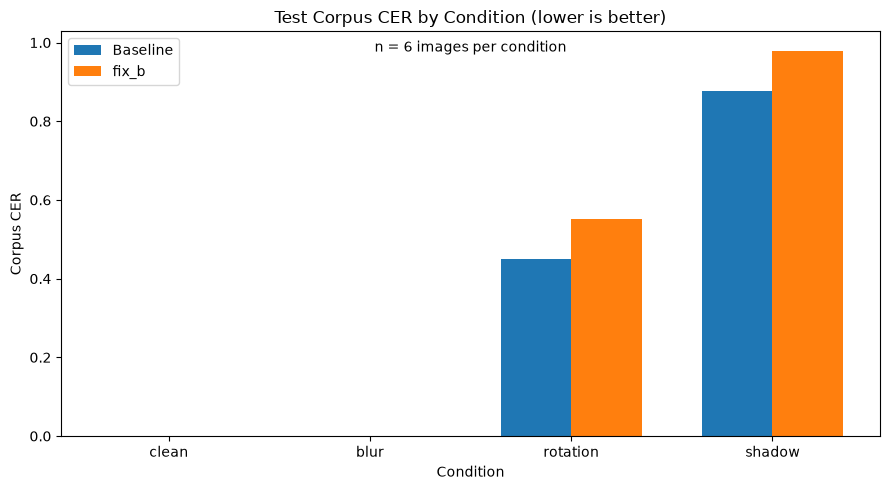

In [49]:
# TODO (5 marks): ONE bar chart of TEST corpus CER per condition (4 groups), baseline vs chosen recipe.
# Axis labels, a title that says "lower is better", and "n = 6 images per condition" somewhere on the figure.

baseline_cer = []
chosen_cer = []

for condition in CONDITIONS:
    base_part = test_base[test_base["condition"] == condition]
    chosen_part = test_final[test_final["condition"] == condition]

    baseline_cer.append(score(list(base_part["norm_reference"]),
                              list(base_part["norm_prediction"]))["cer"])
    chosen_cer.append(score(list(chosen_part["norm_reference"]),
                            list(chosen_part["norm_prediction"]))["cer"])

x = range(len(CONDITIONS))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar([i - width/2 for i in x], baseline_cer, width, label="Baseline")
plt.bar([i + width/2 for i in x], chosen_cer, width, label=CHOSEN)

plt.xlabel("Condition")
plt.ylabel("Corpus CER")
plt.title("Test Corpus CER by Condition (lower is better)")
plt.xticks(list(x), CONDITIONS)
plt.text(0.5, 0.95, "n = 6 images per condition",
         transform=plt.gca().transAxes, ha="center")
plt.legend()
plt.tight_layout()
plt.show()

No improvement example exists.
UNCHANGED: images/T01_clean.png
REGRESSION: images/T02_rotation.png


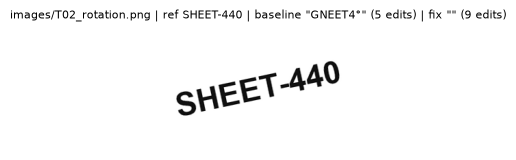

In [51]:
# TODO (6 marks with the explanations below): pick THREE test examples with show_example(filename, test_base, test_final):
# ideally one improvement, one unchanged, one regression. If a kind does not exist, say so and pick another example.

comparison = test_base[["filename", "condition", "norm_reference", "norm_prediction", "edits"]].merge(
    test_final[["filename", "norm_prediction", "edits"]],
    on="filename",
    suffixes=("_base", "_final")
)

improvements = comparison[comparison["edits_final"] < comparison["edits_base"]]
unchanged = comparison[comparison["edits_final"] == comparison["edits_base"]]
regressions = comparison[comparison["edits_final"] > comparison["edits_base"]]

if len(improvements) > 0:
    improvement = improvements.iloc[0]
    print("IMPROVEMENT:", improvement["filename"])
    show_example(improvement["filename"], test_base, test_final)
else:
    print("No improvement example exists.")

if len(unchanged) > 0:
    same = unchanged.iloc[0]
    print("UNCHANGED:", same["filename"])
    for filename in test_base["filename"].unique():
        _files[filename] = _files[os.path.basename(filename)]
else:
    print("No unchanged example exists.")

if len(regressions) > 0:
    regression = regressions.iloc[0]
    print("REGRESSION:", regression["filename"])
    show_example(regression["filename"], test_base, test_final)
else:
    print("No regression example exists.")

**Examples** (2–3 sentences each: first say what you *see* in the image, then, separately, what you *guess* happened):

1. *(write here)*
2. *(write here)*
3. *(write here)*

**Recommendation (80–150 words, 2 marks):** which recipe you would keep, which condition still needs work, and what these 48 synthetic images cannot tell you.

**Your answer:** *(write here)*

**Two short answers (2 marks):** (a) Why can exact match matter more than a small CER for a product code? (b) Why can this crop-based test not tell you whether a detector misses labels in full photographs?

**Your answers:** *(write here)*

# Sources and help
List every source (docs, articles, people) you used. Say clearly which parts you wrote yourself.

**Your note:** *(write here)*

**Submit on Teams before the next lecture begins:** this executed notebook, `predictions.csv` (120 rows) and `chosen_config.json`. After the lecture starts, homework is not accepted.